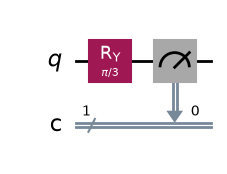

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from math import pi

# Create a circuit with exactly 1 qubit and 1 classical bit
qc = QuantumCircuit(1, 1)

# Rotate the qubit by 60 degrees
qc.ry(pi/3, 0)

# Measure the qubit
qc.measure(0, 0)

# Display the circuit
qc.draw("mpl")

In [3]:
simulator = AerSimulator()

job = simulator.run(qc, shots=100)
result = job.result()
counts = result.get_counts()

print("Measurement results:", counts)
print("Number of shots:", sum(counts.values()))

Measurement results: {'0': 76, '1': 24}
Number of shots: 100


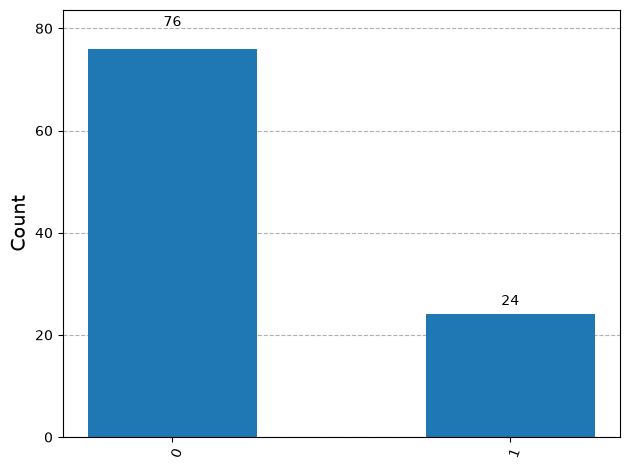

In [4]:
plot_histogram(counts)

Circuit A — favors 0: {'1': 19, '0': 81}
Circuit B — favors 1: {'1': 82, '0': 18}


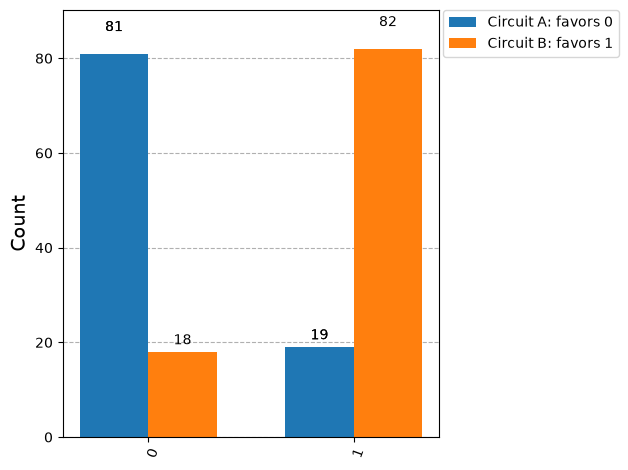

In [5]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from math import pi

simulator = AerSimulator()

# Circuit A: 0 occurs more frequently
qc0 = QuantumCircuit(1, 1)
qc0.ry(pi/3, 0)
qc0.measure(0, 0)

# Circuit B: 1 occurs more frequently
qc1 = QuantumCircuit(1, 1)
qc1.ry(2*pi/3, 0)
qc1.measure(0, 0)

# Execute both circuits for 100 shots
counts0 = simulator.run(qc0, shots=100).result().get_counts()
counts1 = simulator.run(qc1, shots=100).result().get_counts()

print("Circuit A — favors 0:", counts0)
print("Circuit B — favors 1:", counts1)

# Compare both histograms
plot_histogram(
    [counts0, counts1],
    legend=["Circuit A: favors 0", "Circuit B: favors 1"]
)

**Observation and Explanation**

The RY gate changes the quantum state by rotating the qubit. Different rotation angles produce different measurement probabilities. With a rotation of 60°, outcome `0` is more likely, while a rotation of 120° makes outcome `1` more likely. The measurement results fluctuate slightly because quantum measurements are probabilistic. Changing the gate angle allows us to control the bias of the measurement distribution.

**Challenge Question: How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

Quantum gates change the quantum state of a qubit by modifying its probability amplitudes and, in some cases, their relative phases. When the qubit is measured, the squared magnitudes of its amplitudes determine the probabilities of obtaining 0 or 1. For example, an RY gate can rotate the qubit to produce unequal probabilities. Changing its rotation angle changes the measurement distribution, allowing us to make either outcome more likely.